In [287]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [265]:
data = pd.read_excel('/content/EFL Ch 2526 Player Data.xlsx', index_col=0)

In [266]:
data = data[data['minutesPlayed'] >= 1500]

In [267]:
data.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
Index: 333 entries, 2 to 720
Data columns (total 114 columns):
 #    Column                        Non-Null Count  Dtype  
---   ------                        --------------  -----  
 0    accurateChippedPasses         333 non-null    int64  
 1    accurateCrosses               333 non-null    int64  
 2    accurateCrossesPercentage     333 non-null    float64
 3    accurateFinalThirdPasses      333 non-null    int64  
 4    accurateLongBalls             333 non-null    int64  
 5    accurateLongBallsPercentage   333 non-null    float64
 6    accurateOppositionHalfPasses  333 non-null    int64  
 7    accurateOwnHalfPasses         333 non-null    int64  
 8    accuratePasses                333 non-null    int64  
 9    accuratePassesPercentage      333 non-null    float64
 10   aerialDuelsWon                333 non-null    int64  
 11   aerialDuelsWonPercentage      333 non-null    float64
 12   aerialLost                    333 non-null    int64  

In [268]:
data

,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,accuratePassesPercentage,aerialDuelsWon,aerialDuelsWonPercentage,aerialLost,appearances,assists,attemptPenaltyMiss,attemptPenaltyPost,attemptPenaltyTarget,ballRecovery,bigChancesCreated,bigChancesMissed,blockedShots,cleanSheet,clearances,countRating,crossesNotClaimed,directRedCards,dispossessed,dribbledPast,duelLost,errorLeadToGoal,errorLeadToShot,expectedAssists,expectedGoals,fouls,freeKickGoal,goalConversionPercentage,goalKicks,goals,goalsAssistsSum,...,runsOut,savedShotsFromInsideTheBox,savedShotsFromOutsideTheBox,saves,savesCaught,savesParried,scoringFrequency,setPieceConversion,shotFromSetPiece,shotsFromInsideTheBox,shotsFromOutsideTheBox,shotsOffTarget,shotsOnTarget,successfulDribbles,successfulDribblesPercentage,successfulRunsOut,tackles,tacklesWon,tacklesWonPercentage,totalAttemptAssist,totalChippedPasses,totalContest,totalCross,totalDuelsWon,totalDuelsWonPercentage,totalLongBalls,totalOppositionHalfPasses,totalOwnHalfPasses,totalPasses,totalRating,totalShots,totwAppearances,touches,wasFouled,yellowCards,yellowRedCards,player,team,player id,team id
2,123,85,29.82,715,160,47.20,1477,1396,2873,87.46,55,50.00,55,46,2,0,0,0,238,10,0,10,17,64,46,0,0,21,30,134,1,1,9.14,1.74,21,0,6.25,0,2,4,...,0,0,0,0,0,0,2062.50,0.00,1,7,25,16,6,11,57.89,0,81,51,62.96,80,228,19,285,177,56.91,339,1786,1499,3285,340.5,32,6,4032,31,5,0,Matt Grimes,Coventry City,340713,11
3,103,3,21.43,362,212,48.96,956,1661,2617,85.58,155,57.84,113,43,2,0,0,0,174,2,7,6,12,321,43,0,0,8,10,161,0,6,2.15,3.94,30,0,16.28,8,7,9,...,0,0,0,0,0,0,557.14,0.00,0,40,3,20,17,4,57.14,0,36,27,75.00,23,227,7,14,244,60.25,433,1249,1809,3058,316.9,43,7,3840,49,9,0,Taylor Harwood-Bellis,Southampton,980637,45
4,20,44,22.22,333,23,63.89,520,222,742,80.92,9,21.95,32,39,10,0,0,0,107,21,3,18,0,14,39,0,0,50,17,176,0,0,8.07,5.39,16,0,8.14,0,7,17,...,0,0,0,0,0,0,369.43,0.00,8,45,41,31,37,61,50.00,0,22,10,45.45,61,47,122,198,197,52.82,36,661,256,917,285.5,86,8,1753,105,1,0,Leo Scienza,Southampton,1386651,45
6,63,80,27.59,489,86,33.86,882,668,1550,79.16,46,54.76,38,45,6,0,0,0,162,15,2,23,5,85,44,0,0,9,13,109,2,2,9.52,3.37,29,4,14.55,0,8,14,...,0,0,0,0,0,0,428.63,21.05,19,15,40,16,16,18,47.37,0,64,40,62.50,82,187,38,290,171,61.07,254,1189,769,1958,320.6,55,4,3015,44,4,0,Ryan Manning,Southampton,328701,45
7,92,6,16.22,814,116,75.32,1519,1094,2613,92.01,26,50.98,25,43,3,0,0,0,234,3,3,25,9,26,43,0,0,28,59,193,0,4,5.92,3.18,45,0,0.00,0,0,3,...,0,0,0,0,0,0,0.00,0.00,0,26,35,23,13,41,53.25,0,104,70,67.31,57,131,77,37,270,58.32,154,1680,1160,2840,312.9,61,2,3565,100,4,0,Aidan Morris,Middlesbrough,1014841,36
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
638,49,9,21.95,247,66,28.33,484,624,1108,75.89,36,50.70,35,45,1,0,0,0,149,1,1,4,4,113,45,0,0,8,19,109,0,0,1.37,1.68,37,0,5.56,7,1,2,...,0,0,0,0,0,0,3748.00,0.00,0,14,4,9,5,10,50.00,0,59,43,72.88,14,161,20,41,131,54.58,233,746,714,1460,293.5,18,0,2157,26,4,0,Liam Palmer,Sheffield Wednesday,104857,12
646,9,7,10.77,174,14,32.56,235,90,325,67.01,11,10.28,96,44,6,0,0,1,115,12,6,36,1,18,44,0,0,57,21,294,0,0,5.82,11.08,69,0,10.75,0,10,16,...,0,0,0,0,0,0,331.20,0.00,0,57,36,28,29,27,32.53,0,45,27,60.00,44,33,83,65,94,24.23,43,368,117,485,286.5,93,1,1099,11,10,0,Jay Stansfield,Birmingham City,1013987,9
652,3,1,11.11,96,3,42.86,171,82,253,69.32,46,30.87,103,41,4,0,0,1,29,2,14,10,0,33,40,0,0,22,10,166,0,0,0.72,8.01,24,0,9.09,0,5,9,...,0,0,0,0,0,0,416.40,0.00,0,45,10,25,20,7,46.67,0,16,9,56.25,21,4,15,9,100,37.59,7,257,108,365,260.1,55,2,702,31,2,0,Patson Daka,Leicester City,865057,31


In [269]:
passing_cols = [0,1,2,3,4,5,6,7,8,9,14,32,53,60]

In [270]:
scaler = StandardScaler()

In [271]:
players1500_mins = data['player id'].tolist()

In [272]:
data_per90 = pd.read_excel('/content/EFL Ch 2526 Player Data (Per 90).xlsx', index_col=0)

In [273]:
data_per90 = data_per90[data_per90['player id'].isin(players1500_mins)]

In [274]:
data_per90.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
Index: 333 entries, 2 to 720
Data columns (total 114 columns):
 #    Column                        Non-Null Count  Dtype  
---   ------                        --------------  -----  
 0    accurateChippedPasses         333 non-null    float64
 1    accurateCrosses               333 non-null    float64
 2    accurateCrossesPercentage     333 non-null    float64
 3    accurateFinalThirdPasses      333 non-null    float64
 4    accurateLongBalls             333 non-null    float64
 5    accurateLongBallsPercentage   333 non-null    float64
 6    accurateOppositionHalfPasses  333 non-null    float64
 7    accurateOwnHalfPasses         333 non-null    float64
 8    accuratePasses                333 non-null    float64
 9    accuratePassesPercentage      333 non-null    float64
 10   aerialDuelsWon                333 non-null    float64
 11   aerialDuelsWonPercentage      333 non-null    float64
 12   aerialLost                    333 non-null    float64

In [275]:
passing_data_per90 = data_per90.iloc[:, passing_cols]

In [276]:
passing_data_per90

,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,accuratePassesPercentage,assists,expectedAssists,keyPasses,passToAssist
2,2.68,1.85,29.82,15.60,3.49,47.20,32.23,30.46,62.68,87.46,0.04,0.20,1.75,0.00
3,2.38,0.07,21.43,8.35,4.89,48.96,22.06,38.33,60.39,85.58,0.05,0.05,0.55,0.02
4,0.70,1.53,22.22,11.59,0.80,63.89,18.10,7.73,25.82,80.92,0.35,0.28,2.12,0.00
6,1.65,2.10,27.59,12.83,2.26,33.86,23.15,17.53,40.68,79.16,0.16,0.25,2.20,0.05
7,2.36,0.15,16.22,20.91,2.98,75.32,39.03,28.11,67.13,92.01,0.08,0.15,1.46,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
638,1.18,0.22,21.95,5.93,1.58,28.33,11.62,14.98,26.61,75.89,0.02,0.03,0.34,0.00
646,0.24,0.19,10.77,4.73,0.38,32.56,6.39,2.45,8.83,67.01,0.16,0.16,1.20,0.00
652,0.13,0.04,11.11,4.15,0.13,42.86,7.39,3.54,10.94,69.32,0.17,0.03,0.91,0.00
673,0.45,0.03,16.67,4.79,0.13,25.00,8.10,2.70,10.80,58.54,0.03,0.05,0.50,0.00


In [277]:
scaled_passing_data_per90 = pd.DataFrame(scaler.fit_transform(passing_data_per90),
                                         columns=passing_data_per90.columns,
                                         index=passing_data_per90.index)

In [278]:
scaled_passing_data_per90

,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,accuratePassesPercentage,assists,expectedAssists,keyPasses,passToAssist
2,2.221788,2.954841,0.809827,2.557606,0.937998,0.470904,3.041430,1.669399,2.651026,1.234898,-0.487769,1.816923,1.584139,-0.373692
3,1.799142,-0.651271,0.197005,0.458589,1.801209,0.617854,1.381531,2.510893,2.473710,1.027387,-0.357723,-0.575782,-0.518225,0.858382
4,-0.567674,2.306551,0.254708,1.396632,-0.720602,1.864420,0.735199,-0.760989,-0.203071,0.513026,3.543646,3.093032,2.232367,-0.373692
6,0.770704,3.461317,0.646943,1.755637,0.179604,-0.642907,1.559436,0.286868,0.947550,0.318760,1.072779,2.614491,2.372525,2.706495
7,1.770966,-0.489198,-0.183544,4.094955,0.623542,2.818758,4.151294,1.418127,2.995593,1.737117,0.032414,1.019355,1.076067,-0.373692
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
638,0.108559,-0.347385,0.234987,-0.242049,-0.239670,-1.104629,-0.322436,0.014212,-0.141901,-0.042176,-0.747860,-0.894809,-0.886139,-0.373692
646,-1.215731,-0.408162,-0.581622,-0.589472,-0.979566,-0.751449,-1.176051,-1.325549,-1.518619,-1.022332,1.072779,1.178868,0.620555,-0.373692
652,-1.370701,-0.712048,-0.556788,-0.757394,-1.133711,0.108540,-1.012836,-1.209002,-1.355240,-0.767359,1.202825,-0.894809,0.112484,-0.373692
673,-0.919879,-0.732307,-0.150675,-0.572101,-1.133711,-1.382664,-0.896953,-1.298818,-1.366081,-1.957234,-0.617814,-0.575782,-0.605824,-0.373692


In [279]:
# RATING FORMULA = 100 / (1 + np.exp(-0.8 * scaled_passing_data_per90))

In [280]:
passing_rating_data_per90 = 100 / (1 + np.exp(-0.8 * scaled_passing_data_per90))
passing_rating_data_per90.describe()

,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,accuratePassesPercentage,assists,expectedAssists,keyPasses,passToAssist
count,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000
mean,49.324522,48.900523,49.607399,49.546850,49.016839,49.507663,49.578032,49.459549,49.631747,50.755202,49.207043,49.404926,49.607481,48.400434
std,17.156378,16.693222,16.389131,17.201350,16.453366,17.154777,17.315925,17.564209,17.828074,17.107420,17.113834,17.489462,17.767479,14.486739
min,22.390072,34.649829,25.074798,18.873346,27.466272,5.863423,17.860836,23.764163,20.720078,4.222199,30.866646,24.998723,23.407422,42.581323
25%,36.196526,36.132029,39.044779,36.203550,36.315794,36.005874,36.243911,33.975369,35.113982,40.658045,30.866646,35.703956,33.919942,42.581323
50%,47.102690,41.514480,51.850252,48.170844,45.955354,47.397289,48.350410,46.738982,48.045696,53.675343,42.893968,48.056159,49.796920,42.581323
75%,60.197320,58.369665,60.193707,60.407145,56.635612,60.718699,61.151139,61.271532,62.921368,64.105844,60.875385,60.650650,60.834982,42.581323
max,95.284089,96.671257,99.141169,97.765535,96.561354,95.021662,96.514342,93.460447,91.655807,81.902937,97.508875,93.875360,93.078482,99.637043


In [281]:
passing_rating_data_per90

,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,accuratePassesPercentage,assists,expectedAssists,keyPasses,passToAssist
2,85.537930,91.403059,65.652836,88.555142,67.926542,59.308255,91.932003,79.175214,89.291046,72.867651,40.366553,81.054241,78.028206,42.581323
3,80.834839,37.261455,53.931961,59.070267,80.860442,62.111486,75.123781,88.170901,87.857110,69.464154,42.893968,38.683740,39.781437,66.523376
4,38.837714,86.356734,55.076606,75.348864,35.974254,81.630873,64.294264,35.233494,45.947492,60.118870,94.453376,92.232943,85.642312,42.581323
6,64.943658,94.098044,62.657575,80.289848,53.585920,37.418007,77.687522,55.712320,68.092804,56.340882,70.228929,89.008339,86.966726,89.708026
7,80.483200,40.339028,46.335709,96.359498,62.218515,90.508147,96.514342,75.666872,91.655807,80.054338,50.648239,69.327682,70.283901,42.581323
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
638,52.169825,43.096674,54.685941,45.174093,45.221232,29.241095,43.586804,50.284229,47.165033,49.156567,35.473545,32.830803,32.983947,42.581323
646,27.436567,41.908524,38.572981,38.424284,31.353320,35.407849,28.073046,25.722547,22.883603,30.621690,70.228929,71.972435,62.162331,42.581323
652,25.038491,36.132029,39.044779,35.299159,28.762056,52.169433,30.783318,27.543864,25.271350,35.117299,72.357400,32.830803,52.248160,42.581323
673,32.390074,35.758864,46.990148,38.753610,28.762056,24.859279,32.792991,26.133244,25.107927,17.281783,37.889252,38.683740,38.115256,42.581323


In [282]:
w1 = 0.14
w2 = 0.02
passing_weights = pd.Series([w2,w1,w2,w1,w1,w2,w2,w2,w1,w2,w2,w1,w1,w2],
                            index=passing_rating_data_per90.columns)
passing_cols_labels = (passing_rating_data_per90.columns).tolist()
print(len(passing_weights))
print(len(passing_cols_labels))
print(sum(passing_weights))

14
14
1.0


In [283]:
passing_rating_data_per90['overall_rating'] = passing_rating_data_per90 @ passing_weights

In [292]:
passing_rating_data_per90['player'] = data_per90['player']
passing_rating_data_per90 = passing_rating_data_per90.sort_values('overall_rating', ascending=False)

In [293]:
passing_rating_data_per90

,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,accuratePassesPercentage,assists,expectedAssists,keyPasses,passToAssist,overall_rating,player
9,95.129809,85.373546,65.229956,87.979572,71.264038,80.795305,88.266622,72.907610,84.221739,73.474345,83.012011,82.936724,81.631275,89.708026,82.047439,Imrân Louza
2,85.537930,91.403059,65.652836,88.555142,67.926542,59.308255,91.932003,79.175214,89.291046,72.867651,40.366553,81.054241,78.028206,42.581323,80.224588,Matt Grimes
42,95.284089,88.156277,64.497518,88.948187,73.817239,58.077578,86.143846,62.802431,77.663502,59.822102,60.875385,79.016620,78.028206,42.581323,78.589890,Barry Bannan
14,60.467052,75.323017,57.776897,97.765535,49.399373,74.638221,95.674610,60.640442,85.586529,71.068900,76.320515,87.696327,88.331066,42.581323,78.557618,Hayden Hackney
22,69.411608,90.744553,62.493364,87.531642,55.420441,58.742848,78.447590,37.871075,56.326668,51.231344,97.508875,93.099256,89.438046,84.189100,76.956401,Gustavo Hamer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
514,26.990088,34.649829,25.074798,31.190943,30.824951,84.253699,30.092183,26.581528,24.312798,46.074002,42.893968,32.830803,36.152447,42.581323,33.085480,Divin Mubama
720,23.183200,37.641112,63.987448,27.404732,27.861093,19.152865,24.557814,25.090341,21.006441,21.401699,30.866646,38.683740,45.256109,42.581323,32.715879,Bailey Cadamarteri
290,22.390072,34.649829,25.074798,31.640076,29.989941,80.197605,25.315435,24.153759,20.720078,27.634161,42.893968,35.703956,34.868678,42.581323,32.064980,Milutin Osmajić
577,24.409243,34.649829,25.074798,32.701370,29.066209,36.592775,25.837361,24.881917,21.410127,14.878559,55.823552,41.750727,33.606500,42.581323,32.047457,Thomas Cannon


In [308]:
top_passers = passing_rating_data_per90[passing_rating_data_per90['overall_rating'] > 65]

Text(0.5, 1.0, 'Championship 25/26 Top Passers (All Positions)')

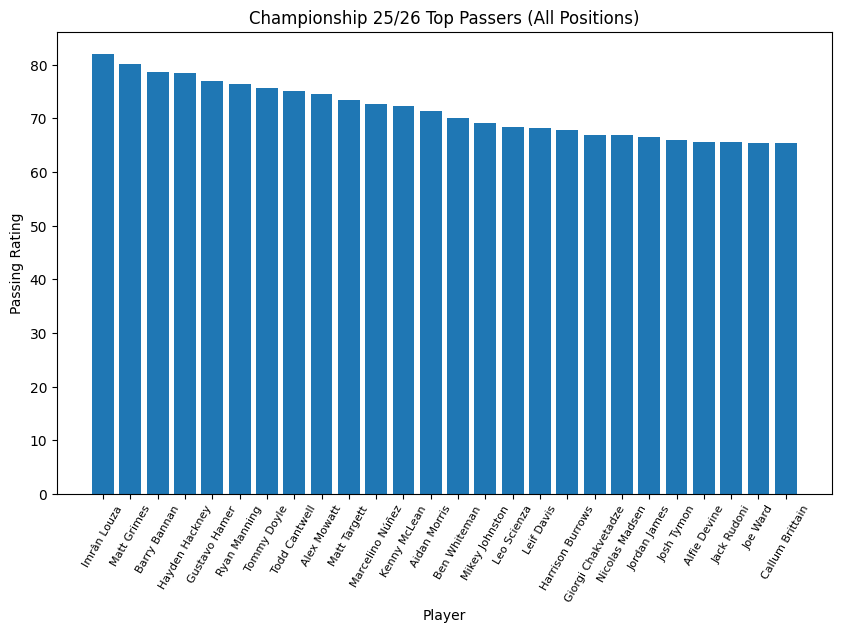

In [348]:
plt.figure(figsize=(10,6))
plt.bar(top_passers['player'], top_passers['overall_rating'])
plt.xticks(rotation=60, size=8)
plt.xlabel('Player')
plt.ylabel('Passing Rating')
plt.title('Championship 25/26 Top Passers (All Positions)')

In [316]:
scaled_passing_data_per90['overall_rating'] = scaled_passing_data_per90 @ passing_weights

In [317]:
scaled_passing_data_per90

,accurateChippedPasses,accurateCrosses,accurateCrossesPercentage,accurateFinalThirdPasses,accurateLongBalls,accurateLongBallsPercentage,accurateOppositionHalfPasses,accurateOwnHalfPasses,accuratePasses,accuratePassesPercentage,assists,expectedAssists,keyPasses,passToAssist,overall_rating
2,2.221788,2.954841,0.809827,2.557606,0.937998,0.470904,3.041430,1.669399,2.651026,1.234898,-0.487769,1.816923,1.584139,-0.373692,1.922090
3,1.799142,-0.651271,0.197005,0.458589,1.801209,0.617854,1.381531,2.510893,2.473710,1.027387,-0.357723,-0.575782,-0.518225,0.858382,0.579042
4,-0.567674,2.306551,0.254708,1.396632,-0.720602,1.864420,0.735199,-0.760989,-0.203071,0.513026,3.543646,3.093032,2.232367,-0.373692,1.238860
6,0.770704,3.461317,0.646943,1.755637,0.179604,-0.642907,1.559436,0.286868,0.947550,0.318760,1.072779,2.614491,2.372525,2.706495,1.720739
7,1.770966,-0.489198,-0.183544,4.094955,0.623542,2.818758,4.151294,1.418127,2.995593,1.737117,0.032414,1.019355,1.076067,-0.373692,1.532273
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
638,0.108559,-0.347385,0.234987,-0.242049,-0.239670,-1.104629,-0.322436,0.014212,-0.141901,-0.042176,-0.747860,-0.894809,-0.886139,-0.373692,-0.429934
646,-1.215731,-0.408162,-0.581622,-0.589472,-0.979566,-0.751449,-1.176051,-1.325549,-1.518619,-1.022332,1.072779,1.178868,0.620555,-0.373692,-0.344968
652,-1.370701,-0.712048,-0.556788,-0.757394,-1.133711,0.108540,-1.012836,-1.209002,-1.355240,-0.767359,1.202825,-0.894809,0.112484,-0.373692,-0.743281
673,-0.919879,-0.732307,-0.150675,-0.572101,-1.133711,-1.382664,-0.896953,-1.298818,-1.366081,-1.957234,-0.617814,-0.575782,-0.605824,-0.373692,-0.849967


In [337]:
sigmoid_x = np.arange(-3, 3.1, step=0.1)
sigmoid_y = []
for i in sigmoid_x:
  sigmoid_y.append(1 / (1 + np.exp(-i)))

[]

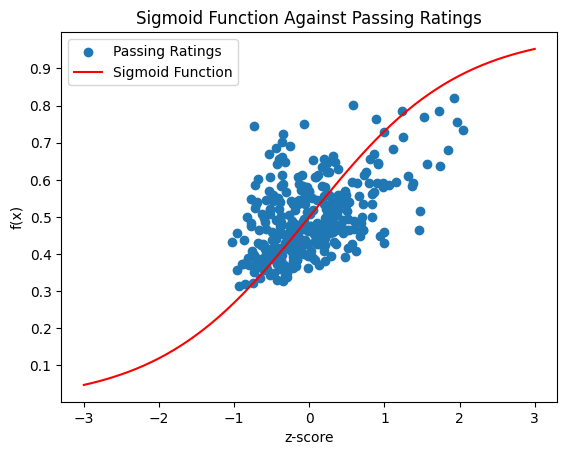

In [345]:
plt.scatter(scaled_passing_data_per90['overall_rating'], passing_rating_data_per90['overall_rating'] / 100, label='Passing Ratings')
plt.plot(sigmoid_x, sigmoid_y, color='red', label = 'Sigmoid Function')
plt.xticks(np.arange(-5, 5.1, step=1))
plt.yticks(np.arange(0, 1.5, step=0.1))
plt.xlabel('z-score')
plt.ylabel('f(x)')
plt.legend()
plt.title('Sigmoid Function Against Passing Ratings')
plt.plot()